In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# 1. Cargar el dataset (64 píxeles por imagen, números del 0 al 9)
digits = load_digits()
X = digits.data
y = digits.target

print(f"Total de imágenes: {X.shape[0]}")
print(f"Píxeles por imagen: {X.shape[1]} (8x8)")

Total de imágenes: 1797
Píxeles por imagen: 64 (8x8)


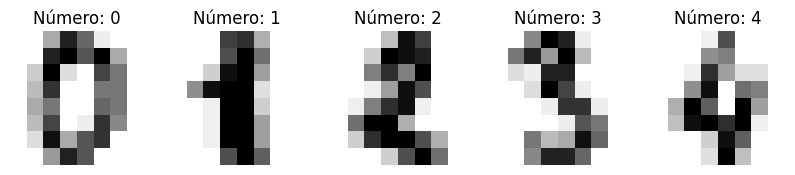

In [3]:
# Mostrar algunos ejemplos aleatorios
fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(f'Número: {label}')
plt.show()

In [4]:
# Escalado simple (Min-Max scaling manual)
# Al dividir entre 16.0, todos los valores quedan entre 0 y 1.
X_scaled = X / 16.0

# Separar en Train y Test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

print("Datos preparados y escalados.")

Datos preparados y escalados.


In [5]:
# Entrenar Regresión Logística
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train, y_train)

# Evaluar
y_pred_log = log_model.predict(X_test)
acc_log = accuracy_score(y_test, y_pred_log)

print(f"Precisión Regresión Logística: {acc_log:.2%}")

Precisión Regresión Logística: 96.67%


In [6]:
# Entrenar Red Neuronal (MLP)
# Dos capas ocultas: una de 64 neuronas y otra de 32
nn_model = MLPClassifier(hidden_layer_sizes=(64, 32),
                         max_iter=1000,
                         random_state=42)

nn_model.fit(X_train, y_train)

# Evaluar
y_pred_nn = nn_model.predict(X_test)
acc_nn = accuracy_score(y_test, y_pred_nn)

print(f"Precisión Red Neuronal: {acc_nn:.2%}")

Precisión Red Neuronal: 97.22%


--- RESULTADO FINAL ---
Regresión Logística: 96.67%
Red Neuronal:        97.22%

La Red Neuronal GANÓ. Capturó mejor las formas complejas.


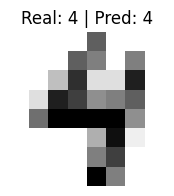

In [7]:
print(f"--- RESULTADO FINAL ---")
print(f"Regresión Logística: {acc_log:.2%}")
print(f"Red Neuronal:        {acc_nn:.2%}")

if acc_nn > acc_log:
    print("\nLa Red Neuronal GANÓ. Capturó mejor las formas complejas.")
else:
    print("\nEmpate técnico.")

# --- BONUS: Ver dónde se equivocó o acertó ---
# Tomamos una imagen del test set
index = 123
imagen_prueba = X_test[index].reshape(8, 8)
etiqueta_real = y_test[index]
prediccion = nn_model.predict([X_test[index]])[0]

plt.figure(figsize=(2, 2))
plt.imshow(imagen_prueba, cmap=plt.cm.gray_r)
plt.title(f"Real: {etiqueta_real} | Pred: {prediccion}")
plt.axis('off')
plt.show()

MODELO                    | ACCURACY   | COMENTARIO
------------------------------------------------------------


c:\Users\Rafael\Dropbox\Rafael\Proyectos\Proyectos_Python\curso_modelado_presentacion_datos\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Modelo A (Simple)         | 97.78%     | Capas: (32,), Act: relu
Modelo B (Profundo)       | 97.78%     | Capas: (64, 32, 16), Act: relu
Modelo C (Vieja Escuela)  | 97.50%     | Capas: (100,), Act: logistic


c:\Users\Rafael\Dropbox\Rafael\Proyectos\Proyectos_Python\curso_modelado_presentacion_datos\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


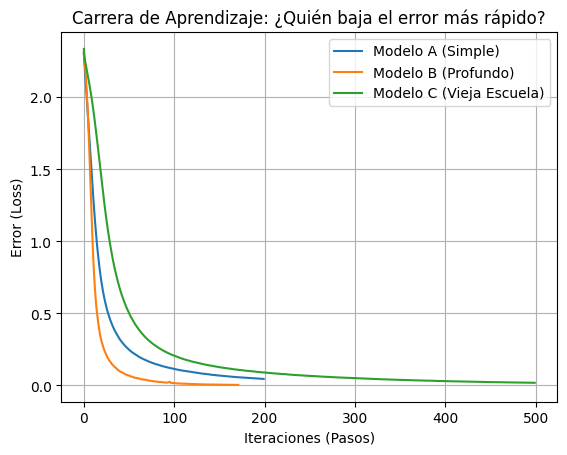

In [8]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Definimos 3 "Candidatos" con configuraciones diferentes
modelos_a_probar = [
    {
        "nombre": "Modelo A (Simple)",
        "capas": (32,),  # Cerebro pequeño
        "activacion": 'relu',
        "iteraciones": 200
    },
    {
        "nombre": "Modelo B (Profundo)",
        "capas": (64, 32, 16), # 3 Capas en embudo
        "activacion": 'relu',
        "iteraciones": 500
    },
    {
        "nombre": "Modelo C (Vieja Escuela)",
        "capas": (100,),
        "activacion": 'logistic', # Usando Sigmoide (suele ser peor)
        "iteraciones": 500
    }
]

print(f"{'MODELO':<25} | {'ACCURACY':<10} | {'COMENTARIO'}")
print("-" * 60)

for config in modelos_a_probar:
    # 1. Instanciar con los parámetros variables
    mlp = MLPClassifier(
        hidden_layer_sizes=config["capas"],
        activation=config["activacion"],
        max_iter=config["iteraciones"],
        random_state=42
    )
    
    # 2. Entrenar
    mlp.fit(X_train, y_train)
    
    # 3. Evaluar
    acc = accuracy_score(y_test, mlp.predict(X_test))
    
    print(f"{config['nombre']:<25} | {acc:.2%}     | Capas: {config['capas']}, Act: {config['activacion']}")

    # Bonus: Ver la curva de aprendizaje (Loss Curve)
    plt.plot(mlp.loss_curve_, label=config['nombre'])

# Mostrar gráfico de aprendizaje
plt.title("Carrera de Aprendizaje: ¿Quién baja el error más rápido?")
plt.xlabel("Iteraciones (Pasos)")
plt.ylabel("Error (Loss)")
plt.legend()
plt.grid(True)
plt.show()